# Jour 2 — Prétraitement du Titanic

Consignes : [Octopus](https://octopus.developers.institute/courses/collection/254/course/812/section/1694/chapter/3305), consultées le 29 octobre 2026. Solutions standards uniquement.

Exécuter toutes les cellules dans l’ordre ; installer les dépendances de `Week2/requirements.txt` si nécessaire.

In [1]:
from pathlib import Path
from urllib.parse import quote
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid")
# Chaque notebook fonctionne seul, y compris dans Colab ; données publiques du cours.
def course_file(repo, path, member=None):
    cache = Path("data"); cache.mkdir(exist_ok=True)
    destination = cache / (member or Path(path).name)
    if not destination.exists():
        suffix = quote(path)
        response = requests.get(f"https://media.githubusercontent.com/media/devtlv/{repo}/main/{suffix}", timeout=180)
        if response.status_code == 404:
            response = requests.get(f"https://raw.githubusercontent.com/devtlv/{repo}/main/{suffix}", timeout=180)
        response.raise_for_status()
        payload = response.content
        if member:
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                matches = [x for x in archive.namelist() if Path(x).name == member and not x.startswith("__MACOSX")]
                if len(matches) != 1: raise ValueError(f"Membre ambigu ou absent : {member}")
                payload = archive.read(matches[0])
        destination.write_bytes(payload)
    return destination


## Exercice 1 — Doublons
Comparer toutes les colonnes évite de supprimer des passagers distincts ayant des caractéristiques communes.

In [2]:
df = pd.read_csv(course_file("Datasets-DA-Bootcamp-2-", "Week 4 - Data Understanding/W4D4 - Data Preprocessing & T/titanic dataset.zip", "train.csv"))
raw = df.copy()
before=len(df); count=int(df.duplicated().sum()); df=df.drop_duplicates().copy()
print({"avant":before,"doublons":count,"après":len(df)})
assert before-len(df)==count and not df.duplicated().any()
display(df.head())

{'avant': 891, 'doublons': 0, 'après': 891}


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Exercice 2 — Valeurs manquantes
Médiane pour Age (robuste aux extrêmes), mode pour Embarked (catégorie), constante Unknown pour Cabin. Une suppression des lignes sans Age est montrée séparément pour mesurer la perte, sans la retenir pour le jeu final.

In [3]:
from sklearn.impute import SimpleImputer
display(df.isna().sum().to_frame("manquants_avant"))
print("Alternative suppression Age :",len(df.dropna(subset=["Age"])),"lignes conservées")
df["AgeMissing"]=df["Age"].isna().astype(int)
df["Age"]=SimpleImputer(strategy="median").fit_transform(df[["Age"]]).ravel()
df["Embarked"]=df["Embarked"].fillna(df["Embarked"].mode().iloc[0])
df["Cabin"]=df["Cabin"].fillna("Unknown")
assert not df.isna().any().any()
display(df.isna().sum().to_frame("manquants_après"))

,manquants_avant
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Alternative suppression Age : 714 lignes conservées


,manquants_après
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## Exercice 3 — Ingénierie des variables
FamilySize inclut le passager lui-même. Les titres sont extraits du nom. Un encodage préliminaire des titres démontre la méthode ; les variables finales seront réunies après le traitement des valeurs extrêmes.

In [4]:
df["FamilySize"]=df["SibSp"]+df["Parch"]+1
df["Title"]=df["Name"].str.extract(r",\s*([^.]*)\.",expand=False).str.strip().fillna("Unknown")
title_demo=pd.get_dummies(df["Title"],prefix="Title",dtype=int)
display(pd.concat([df[["Name","FamilySize","Title"]],title_demo],axis=1).head())

,Name,FamilySize,Title,Title_Capt,Title_Col,Title_Don,Title_Dr,Title_Jonkheer,Title_Lady,Title_Major,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,"Braund, Mr. Owen Harris",2,Mr,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",2,Mrs,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
2,"Heikkinen, Miss. Laina",1,Miss,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",2,Mrs,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,"Allen, Mr. William Henry",1,Mr,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


## Exercice 4 — Valeurs extrêmes
IQR signale des observations à examiner, sans prouver une erreur. Les âges élevés plausibles sont conservés. Pour Fare, on compare le plafonnement au quantile 98 % et log1p ; le plafonnement est retenu comme démonstration, avec conservation du tarif initial. Les seuils doivent être appris sur le train uniquement en modélisation.

Age Q1 22.0 Q3 35.0 IQR 13.0 bornes (2.5, 54.5) extrêmes 66
Fare Q1 7.9104 Q3 31.0 IQR 23.0896 bornes (-26.724, 65.6344) extrêmes 116
Quantiles Fare {0.98: 211.3375, 0.99: 249.00622000000035}


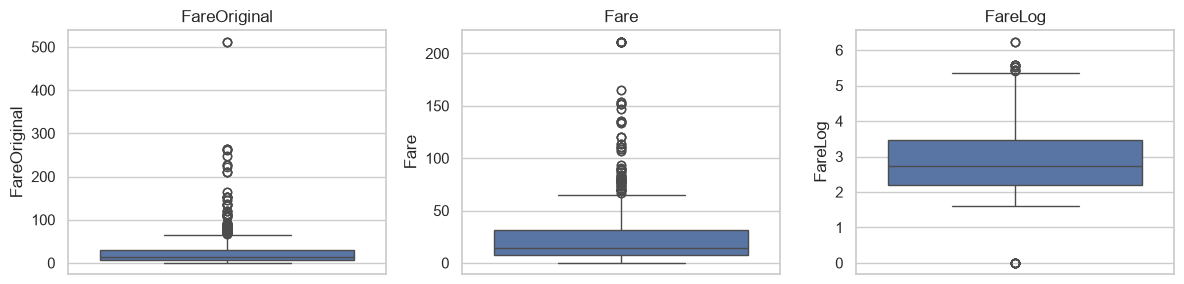

,Age,FareOriginal,Fare,FareLog
count,891.000000,891.000000,891.000000,891.000000
mean,29.361582,32.204208,30.678483,2.962246
std,13.019697,49.693429,39.904946,0.969048
min,0.420000,0.000000,0.000000,0.000000
25%,22.000000,7.910400,7.910400,2.187218
50%,28.000000,14.454200,14.454200,2.737881
75%,35.000000,31.000000,31.000000,3.465736
max,80.000000,512.329200,211.337500,6.240917


In [5]:
for col in ["Age","Fare"]:
    q1,q3=df[col].quantile([.25,.75]); iqr=q3-q1
    mask=(df[col]<q1-1.5*iqr)|(df[col]>q3+1.5*iqr)
    print(col,"Q1",q1,"Q3",q3,"IQR",iqr,"bornes",(q1-1.5*iqr,q3+1.5*iqr),"extrêmes",int(mask.sum()))
print("Quantiles Fare", df["Fare"].quantile([.98,.99]).to_dict())
df["FareOriginal"]=df["Fare"]
cap=df["Fare"].quantile(.98); df["Fare"]=df["Fare"].clip(upper=cap)
df["FareLog"]=np.log1p(df["FareOriginal"])
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,col in zip(axes,["FareOriginal","Fare","FareLog"]):
    sns.boxplot(data=df,y=col,ax=ax);ax.set_title(col)
plt.tight_layout();plt.show()
display(df[["Age","FareOriginal","Fare","FareLog"]].describe())
assert len(df)==before-count

## Exercice 5 — Standardisation et normalisation
Age est standardisé pour comparer des écarts à la moyenne ; cela ne rend pas sa distribution normale. Fare, asymétrique et plafonné, est ramené dans [0,1]. Le jeu non normalisé reste disponible pour l’interprétation.

In [6]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
age_scaled=StandardScaler().fit_transform(df[["Age"]])
fare_scaled=MinMaxScaler().fit_transform(df[["Fare"]])
print("Age moyenne / écart-type population",age_scaled.mean(),age_scaled.std())
print("Fare min / max",fare_scaled.min(),fare_scaled.max())
assert abs(age_scaled.mean())<1e-10 and np.isclose(age_scaled.std(),1)
assert fare_scaled.min()>=0 and fare_scaled.max()<=1+1e-10

Age moyenne / écart-type population 2.272779794518839e-16 1.0
Fare min / max 0.0 1.0


## Exercice 6 — Encodage final
Sex, Embarked et Title sont nominales : one-hot. Pclass est ordinale (ordre 1,2,3), on conserve son codage en précisant que les distances ne sont pas nécessairement égales. Nom, ticket, cabine et identifiants sont exclus de la matrice ; Survived reste la cible séparée.

In [7]:
features=df[["Pclass","Age","SibSp","Parch","Fare","FamilySize","AgeMissing","Sex","Embarked","Title"]].copy()
features=pd.get_dummies(features,columns=["Sex","Embarked","Title"],dtype=int)
features["Age"]=age_scaled.ravel();features["Fare"]=fare_scaled.ravel()
y=df["Survived"].copy()
assert features.select_dtypes(include=["object","string"]).empty
assert np.isfinite(features.to_numpy()).all()
display(features.head())

,Pclass,Age,SibSp,Parch,Fare,FamilySize,AgeMissing,Sex_female,Sex_male,Embarked_C,...,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,3,-0.565736,1,0,0.034305,2,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
1,1,0.663861,1,0,0.337296,2,0,1,0,1,...,0,0,0,0,0,1,0,0,0,0
2,3,-0.258337,0,0,0.037499,1,0,1,0,0,...,0,1,0,0,0,0,0,0,0,0
3,1,0.433312,1,0,0.251257,2,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
4,3,0.433312,0,0,0.038091,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


## Exercice 7 — Groupes d’âge
Les bornes incluent zéro, 12, 18 et 60 ans dans le groupe de gauche. Les groupes sont construits sur Age en années, avant sa standardisation.

In [8]:
groups=pd.cut(df["Age"],bins=[0,12,18,60,100],labels=["child","teen","adult","senior"],include_lowest=True)
assert groups.notna().all()
features=pd.concat([features,pd.get_dummies(groups,prefix="AgeGroup",dtype=int)],axis=1)
display(groups.value_counts(sort=False).to_frame("effectif"))
Path("results").mkdir(exist_ok=True)
features.to_csv("results/titanic_features.csv",index=False)
y.to_csv("results/titanic_target.csv",index=False)
print("Matrice finale",features.shape,"; cible",y.shape)

,effectif
Age,
child,69
teen,70
adult,730
senior,22


Matrice finale (891, 33) ; cible (891,)


### Limites
Prétraitement pédagogique du jeu fourni, sans entraînement de modèle. Pour évaluer un modèle, séparer train/test avant imputation, plafonnement, encodage appris et mise à l’échelle ; utiliser une Pipeline ajustée au train pour éviter toute fuite de données.